### Model inspired by:
- [1] Offshore Pipelaying Dynamics. Gullik Anthon Jensen 
- [2] Modelling and Control of Offshore Marine Pipeline during Pipelay. Gullik A. Jensen et al

### Motion equation used:
M(q)q ̈ + C(q,q ̇)q ̇ + H(q,q ̇)q ̇ + f(q) + g(q) = τ

### Implementation aspects:

- The model can be applied to normal dynamic pipelay condition for control purposes 

In [1]:
import numpy as np
import math
from scipy.integrate import odeint, ode, solve_ivp
from scipy.integrate import ode
from scipy.misc import derivative
from numpy.linalg import inv, pinv
import numdifftools as nd
import tqdm
import functools
from datetime import datetime
from scipy.optimize import fsolve
from scipy.linalg import lu_factor, lu_solve
import plotly.graph_objects as go

In [2]:
%matplotlib inline

In [3]:
import matplotlib.pyplot as plt

### Modelling data:

In [4]:
N = 12  # Number of simulation nodes

In [5]:
pipe_weight_per_unit_length = 179.7 #  (submerged) [kg/m]  

In [6]:
h = 34 # water depth, [m]

In [7]:
dq = np.zeros(N) #  these numbers are used for in itial checks only and redefined below

In [8]:
Fx_0 = 1515*1000 # [N] 
Fx_ = 0.8*Fx_0# [N] 

In [9]:
# Catenary

In [10]:
Ws = pipe_weight_per_unit_length*9.81 # [N/m]

In [11]:
def catenary_z(x, w, Tx):
    a = Tx / w
    return a * (np.cosh(x / a) - 1.0)

def catenary_length(x, w, Tx):
    a = Tx / w
    return a * np.sinh(x / a)

In [12]:
# Inputs
w = Ws       # Effective submerged weight [N/m]
Tx = Fx_0       # Horizontal tension [N]

# Calculate LTD from target water depth
a = Tx / w
LTD = a * np.arccosh(1.0 + h / a)

# Calculate profile
x0 = np.linspace(0.0, LTD, N+1)
y0 = catenary_z(x0, w, Tx)
s0 = catenary_length(x0, w, Tx)

print(f"LTD: {LTD:.2f} m")
print(f"Depth at vessel: {y0[-1]:.2f} m (target: {h:.2f} m)")
print(f"Total suspended pipe length: {s0[-1]:.2f} m")

LTD: 240.95 m
Depth at vessel: 34.00 m (target: 34.00 m)
Total suspended pipe length: 244.12 m


In [13]:
q=[]
l=[]
rad_=[0]

for i in range(len(x0)-1):
    l.append(np.sqrt((x0[i+1]-x0[i])**2+(y0[i+1]-y0[i])**2))
    rad =np.arctan2((y0[i+1]-y0[i]),(x0[i+1]-x0[i]))
    q.append(rad-rad_[-1]) 
    rad_.append(rad)

In [14]:
l

[20.08071072183085,
 20.091673645156536,
 20.11360547585167,
 20.146518185275426,
 20.190429738647605,
 20.24536410487037,
 20.311351269632397,
 20.388427251802053,
 20.47663412311762,
 20.576020031186538,
 20.686639225804228,
 20.80855208860774]

In [15]:
pipe_joint_length = l[0]  # [m]
mn = 39_989_000 # mass of the vessel, [kg]

In [16]:
# L - the hull length
# Xg - x-center of gravity

L = 169 # [m]
Xg = 78 # [m]

In [17]:
# Fossen book p.181
def vessel_inertia_moment(mn, Xg, L):
    r = 0.25*L
    Ir = mn*r**2
    Iz = mn*Xg**2 + Ir
    return Iz

In [18]:
In = vessel_inertia_moment(mn, Xg, L)

In [19]:
In

314675940312.5

In [20]:
mi = [x*pipe_weight_per_unit_length for x in l] # mass of pipe element (submerged), [kg]

In [21]:
# for hydrodynamic damping matrix
Cd=[0.87 for x in range(N)] # Drag coefficient
Cd[-1] = 1.6 

In [22]:
# Pipe
qw = 1025 # Water density [kg/m3]
d0 = 0.508 # Outer diameter of pipe, [m]
dI= (508-33*2)/1000 # Inner diameter of pipe, [m]

In [23]:
# for vector of spring forces in the pipe joints
E = 207e9 # modulus of elasticity of steel, [N/m^2]
EI = E*3.14/64*(d0**4-dI**4) # Bending stiffness [N*m^2]

In [24]:
K = EI

In [25]:
K

288732649.082625

In [26]:
# Time integration params:
max_t = 5 # 12
DP_start = 1 # 3
X_REF = LTD+1

In [27]:
Awp = 6000 # the waterplane area of the vessel, [m^2]
fip = 1e12

In [28]:
# (control S-lay shape, can be adjusted for a certain stinger angle)
tau_qn = 6e5 # tension in pipe at water level, [N] - for vector of control inputs 
tau_q_wave = -9e5 # (derived by RAO),[N]

In [29]:
# (control S-lay shape, can be adjusted for a certain stinger angle)
# (control dynamics)
kp = 2.95e4   
kd = 2.5e4  

### System inertia matrix 

In [30]:
def alpha(q):
    sum_=0
    ans=[]
    for i in range(len(q)):
        sum_+=q[i]
        ans.append(sum_)
    return np.array(ans)

In [31]:
def Jv(q, i, l):
    alp=alpha(q)
    def Jv0(i, k, alp, l):
        
        if k<i:
            tmp1=np.dot(np.array(l[k:i]),np.sin(alp[k:i]))
            tmp1=-tmp1-0.5*l[i]*np.sin(alp[i])
            
            tmp2 =np.dot(np.array(l[k:i]),np.cos(alp[k:i]))
            tmp2=tmp2+0.5*l[i]*np.cos(alp[i])
                        
            return np.array([tmp1, tmp2]).T
        elif k==i:
            return np.array([-0.5*l[i]*np.sin(alp[i]),
                    0.5*l[i]*np.cos(alp[i])]).T
        else:
            return np.array([0, 0]).T                 
    
    ans=np.array([Jv0(i, k, alp, l) for k in range(len(q))])
    
    return ans.T

In [32]:
Jv(q, 2, l)

array([[-1.52522569, -1.29064455, -0.58677305,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ],
       [50.19835124, 30.11901074, 10.03967025,  0.        ,  0.        ,
         0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
         0.        ,  0.        ]])

In [33]:
def Jomega(i,q):

    def Jomega0(i,k):
        if k<=i:
            return 1
        return 0
    ans=np.array([Jomega0(i, k) for k in range(len(q))])
   
    return ans.reshape(len(q),1).T

In [34]:
def M(q, l, mn, In, mi):
  
    sum1 = mn * np.dot(Jv( q, len(q)-1, l).T, Jv(q, len(q)-1, l))
    
    sum2 = In * np.dot(Jomega(len(q)-1,q).T, Jomega(len(q)-1,q))

    sum3 = 0
    
    for i in range(len(q)-1):
        J_v = Jv(q, i, l)
        sum3+=mi[i]*np.dot(J_v.T, J_v)
      
    return (sum1 + sum2 + sum3)

In [35]:
M(q, l, mn, In, mi)

array([[2.48667588e+12, 2.30088160e+12, 2.11450177e+12, 1.92753737e+12,
        1.73998908e+12, 1.55185726e+12, 1.36314198e+12, 1.17384301e+12,
        9.83959852e+11, 7.93491692e+11, 6.02437455e+11, 4.10795791e+11],
       [2.30088160e+12, 2.13122737e+12, 1.96099090e+12, 1.79017282e+12,
        1.61877380e+12, 1.44679422e+12, 1.27423414e+12, 1.10109335e+12,
        9.27371351e+11, 7.53067347e+11, 5.78180275e+11, 4.02708799e+11],
       [2.11450177e+12, 1.96099090e+12, 1.80691066e+12, 1.65226094e+12,
        1.49704206e+12, 1.34125443e+12, 1.18489813e+12, 1.02797300e+12,
        8.70478546e+11, 7.12414045e+11, 5.53778479e+11, 3.94570571e+11],
       [1.92753737e+12, 1.79017282e+12, 1.65226094e+12, 1.51380127e+12,
        1.37479344e+12, 1.23523750e+12, 1.09513361e+12, 9.54481638e+11,
        8.13281188e+11, 6.71531599e+11, 5.29231949e+11, 3.86381065e+11],
       [1.73998908e+12, 1.61877380e+12, 1.49704206e+12, 1.37479344e+12,
        1.25202721e+12, 1.12874278e+12, 1.00493998e+12, 8.80

### Coriolis-centripetal matrix

In [36]:
def C(q, dq, l, mn, In, mi): 
    ans = np.zeros((len(q),len(q)))              
    fun = lambda q: M(q, l, mn, In, mi)
    Dfun = nd.Gradient(fun) 
    
    diff = Dfun(q)

    
    def c(i,j,k):
        return 0.5 *(diff[k].item((i,j))+
                     diff[j].item((i,k))-
                     diff[i].item((j,k)))
    
    for i in range(len(q)):
        for j in range(len(q)):
            for k in range(len(q)):
                ans[i][j]+=c(i,j,k)*dq[k]
    return ans    

In [37]:
C(q, dq, l, mn, In, mi)

array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])

### Hydrodynamic damping matrix

In [38]:
def R_I_Bi(i, alp):
    return np.array([[np.cos(alp[i]), -np.sin(alp[i])],
                    [np.sin(alp[i]), np.cos(alp[i])]])

In [39]:
alp=alpha(q)
dalp=alpha(dq)

In [40]:
R_I_Bi(2, alp)

array([[ 0.99829643, -0.05834588],
       [ 0.05834588,  0.99829643]])

In [41]:
I_=np.array([[0,0],
             [0,1]])

In [42]:
def Pi(i,alp):
    return np.dot(np.dot(R_I_Bi(i, alp),I_),R_I_Bi(i, alp).T)

In [43]:
def mod_Vn(q, alp, dq):
    ans=[]
    for j in range(len(q)):
        ans.append(np.dot(np.dot(Pi(j,alp),Jv( q,j, l)), dq))
    return np.linalg.norm(np.array(ans))

In [44]:
mod_Vn(q,alp,dq)

0.0

In [45]:
def mod_Vni(i,q,alp,dq):
    return np.linalg.norm(np.dot(np.dot(Pi(i,alp),Jv( q,i, l)), dq))

In [46]:
mod_Vni(len(q)-1,q,alp,dq)

0.0

In [47]:
def gamma(i):
    return 0.5*Cd[i]*qw*d0*l[i]

In [48]:
def H(alp,q,dq,l):
    ans=np.zeros((len(q), len(q)))
    alp=alpha(q)
    for j in range(len(q)):
        ans+=gamma(j)*mod_Vni(j,q,alp,dq)*np.dot(np.dot(Jv(q,j,l).T,Pi(j,alp)),Jv( q,j, l))
    return ans    

In [49]:
alp

array([0.01168218, 0.03504016, 0.05837904, 0.08168612, 0.10494882,
       0.12815465, 0.15129129, 0.17434661, 0.19730869, 0.22016584,
       0.24290667, 0.26552007])

In [50]:
H(alp,q,dq,l)

array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])

### Vector of spring forces in the pipe joints

In [51]:
def f(q,k):
    ans=np.array([k*q[i] for i in range(len(q))])
    return ans.reshape(len(q),1)

### Vector of gravitational/buoyancy forces

In [52]:
def x_(alp,i,l):
    tmp1=np.dot(np.array(l[:i]),np.cos(alp[:i]))

    tmp1+=0.5*l[i]*np.cos(alp[i])
    return tmp1

In [53]:
x_(alp,2,l)

50.19835124162549

In [54]:
def y_(alp,i,l):
    tmp1=np.dot(np.array(l[:i]),np.sin(alp[:i]))
    tmp1+=0.5*l[i]*np.sin(alp[i])
    return tmp1

In [55]:
y_(alp,2,l)

1.52522569271144

In [56]:
G=np.array([0,-9.81]).T

def ggi(i,G):
    return mi[i]*G
   
    
def gbi(G,l,i):
    return -3.14*l[i]*(d0**2/4)*qw*G 


def gt(alp, dalp, fip, i): 
    return -fip*(alp[i] - dalp[i])


In [57]:
def g(q, alp, dalp):
    sum_=0
    for i in range(len(q)-1):
        sum_+=np.dot(Jv( q,i, l).T,ggi(i,G)+gbi(G,l,i))
    tmp = -qw*Awp*(y_(alp,len(alp)-1,l)-h)*G 
    sum_ += np.dot(Jv(q,len(q)-1, l).T, tmp) 
    ans = sum_.reshape(len(q),1) +np.dot(Jomega(len(q)-1,q).T, gt(alp,dalp,fip, len(q)-1))
    return  ans 

In [58]:
g(q,alp, dalp)

array([[-3.03548461e+11],
       [-3.00242227e+11],
       [-2.96935883e+11],
       [-2.93629428e+11],
       [-2.90322863e+11],
       [-2.87016186e+11],
       [-2.83709398e+11],
       [-2.80402498e+11],
       [-2.77095487e+11],
       [-2.73788363e+11],
       [-2.70481125e+11],
       [-2.67173775e+11]])

### Vector of control inputs

In [59]:
# Assume that the stinger is shorter than the link length li for any link i
def tau_q(q,tau_qn): 
    ans= np.array([0 for i in range(len(q))]).reshape(len(q),1)
    ans[-1] = tau_qn
    return ans

In [60]:
def Fx(q,alp,dq,kp, kd, x_ref = 0):
    return -kp*(x_(alp,len(q)-1,l)-x_ref) - kd*mod_Vn(q,alp,dq)

In [61]:
Fx(q,alp,dq,kp, kd, x_ref = X_REF)

325670.2723255907

In [62]:
# F1=np.array([Fx_,0]).reshape(2,1) # actuates the vessel in the surge direction in frame Bn
F1= np.array([-Fx(q, alp, dq, kp, kd, x_ref = X_REF),0]).reshape(2,1) 
def tau_t(q, F):
    tmp= np.dot(Jv(q,len(q)-1, l).T, F)
    return tmp

In [63]:
tau_t(q, F1)

array([[10183644.92146991],
       [10107248.81620182],
       [ 9878018.79437562],
       [ 9495829.71515755],
       [ 8960472.93458538],
       [ 8271656.19166558],
       [ 7429003.44882325],
       [ 6432054.68661603],
       [ 5280265.65260101],
       [ 3973007.56421785],
       [ 2509566.76552462],
       [  889144.3376002 ]])

In [64]:
y_(alp,0,l),y_(alp,len(q)-1,l)

(0.11729057233647737, 31.269801964880443)

In [65]:
def tau_wave(q, alp, tau_q_wave): 
    A0 = tau_q_wave         
    k = 0.5          
    ans=[]
    for i in range(len(q)):
        ans.append([tau_q_wave * np.exp(-k * (y_(alp,len(q)-1,l)-y_(alp,i,l)))])   
    return np.array(ans)

In [66]:
def tau(q, alp, tau_qn, F, tau_q_wave):
    return tau_t(q, F) + tau_wave(q, alp, tau_q_wave) +tau_q(q,tau_qn)

In [67]:
tau_wave(q,alp, tau_q_wave)

array([[-1.54725043e-01],
       [-1.95637369e-01],
       [-3.12816634e-01],
       [-6.32682714e-01],
       [-1.61922499e+00],
       [-5.24658030e+00],
       [-2.15363489e+01],
       [-1.12080297e+02],
       [-7.40182775e+02],
       [-6.20938710e+03],
       [-6.62464827e+04],
       [-9.00000000e+05]])

In [68]:
tau(q, alp, tau_qn, F1, tau_q_wave)

array([[10183644.76674486],
       [10107248.62056445],
       [ 9878018.48155898],
       [ 9495829.08247484],
       [ 8960471.31536039],
       [ 8271650.94508529],
       [ 7428981.9124743 ],
       [ 6431942.60631933],
       [ 5279525.46982607],
       [ 3966798.17711526],
       [ 2443320.2827925 ],
       [  589144.3376002 ]])

### Stinger and roller reactions

The stinger is a rigid circular arc fixed to the vessel. It rotates with the last link (the vessel/stinger body in this model, held near horizontal by `fip`). Its local frame has the origin at the pipe departure point (node N), `u` along the last link and `v` up. It extends aft (negative `u`) and curves downward.

Each roller is a circle in 2D. The pipe centreline rests on top of it, so the roller centre lies `r_roll + d0/2` below the support arc.

Contact is a one-sided penalty spring-damper between each roller centre and the nearest point on the pipe polyline. Its force acts on the pipe and, with opposite sign, on the vessel (the roller point is a function of `q`). It enters the equations as an external generalised force next to `tau`. Set `STINGER_ON = False` to recover the original model.

**Tip clearance** is the gap between the pipe surface and the stinger tip point `T`. It is positive when the pipe passes clear of the tip, and negative when the tip point lies above the pipe centreline (the pipe would hit the structure).

Resolution note: the pipe is a chain of straight links, so it can only follow the stinger curvature if several links lie within the stinger length. The cell below prints a warning if they don't.

In [69]:
STINGER_ON = True      # False -> original model without stinger contact

# Stinger: rigid circular arc fixed to the vessel (rotates with the last link).
# Local frame: origin at pipe departure point (node N), u along last link (forward), v up.
R_st        = 419.0   # radius of the pipe support curve (pipe centreline) [m] - tune to your stinger
st_start    = 0.0      # arc length aft of the departure point to the first roller [m]
n_roll      = 7        # number of rollers
roll_pitch  = 5.0      # arc spacing between rollers [m]
r_roll      = 0.30     # roller radius [m]
tip_ext     = 1.5      # stinger structure beyond the last roller, along the arc [m]
k_roll      = 5e7      # roller contact stiffness [N/m] (penalty)
c_roll      = 2e5      # roller contact damping [N*s/m] (acts only while the pipe closes on the roller)

rho_c = r_roll + d0/2  # roller centre to pipe centreline distance when in contact [m]

In [70]:
# --- stinger geometry in the local frame (constant) ---
th_roll  = (st_start + roll_pitch*np.arange(n_roll)) / R_st          # arc angle of each roller [rad]
roll_loc = np.column_stack([-(R_st - rho_c)*np.sin(th_roll),
                            -R_st + (R_st - rho_c)*np.cos(th_roll)]) # roller centres (u, v)

th_tip  = (st_start + roll_pitch*(n_roll - 1) + tip_ext) / R_st
tip_loc = np.array([-(R_st - rho_c)*np.sin(th_tip),
                    -R_st + (R_st - rho_c)*np.cos(th_tip)])          # stinger tip point (u, v)

def stinger_arc_loc(n=60):
    """Support curve (pipe centreline when resting on the rollers) in the local frame."""
    th = np.linspace(0.0, th_tip, n)
    return np.column_stack([-R_st*np.sin(th), -R_st*(1.0 - np.cos(th))])

def node_xy(q, l):
    """Pipe node coordinates, shape (N+1, 2). Node 0 = touchdown point, node N = departure point."""
    alp = alpha(q)
    l_  = np.asarray(l, dtype=float)
    x = np.concatenate([[0.0], np.cumsum(l_*np.cos(alp))])
    y = np.concatenate([[0.0], np.cumsum(l_*np.sin(alp))])
    return np.column_stack([x, y])

def stinger_to_world(q, p_loc):
    """Local stinger points (n,2) or (2,) -> inertial frame, using node N and the last link angle."""
    q   = np.asarray(q, dtype=float)
    alp = alpha(q)
    a   = alp[-1]
    R   = np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]])
    PN  = node_xy(q, l)[-1]
    return PN + np.atleast_2d(p_loc) @ R.T

# resolution check
_u_st = (st_start + roll_pitch*(n_roll - 1) + tip_ext)
_links_on_stinger = _u_st / float(np.mean(l[-3:]))
print(f"stinger length (arc) = {_u_st:.1f} m, last link lengths ~ {np.mean(l[-3:]):.1f} m -> {_links_on_stinger:.1f} links on the stinger")
if _links_on_stinger < 3:
    print("WARNING: fewer than 3 links on the stinger - the pipe cannot follow the stinger curvature. Increase N.")

stinger length (arc) = 31.5 m, last link lengths ~ 20.7 m -> 1.5 links on the stinger


In [71]:
def Jpoint(alp, l, j, t):
    """Jacobian (2 x N) of the point at fraction t along link j w.r.t. the joint coordinates q.
    Same as Jv(q, j, l) when t = 0.5."""
    N_  = len(alp)
    e   = np.vstack([-np.sin(alp), np.cos(alp)]) * np.asarray(l, dtype=float)   # d(link end)/d(alpha_m)
    J   = np.zeros((2, N_))
    acc = t * e[:, j]
    J[:, j] = acc
    for k in range(j - 1, -1, -1):
        acc = acc + e[:, k]
        J[:, k] = acc
    return J

def Jstinger_point(alp, l, p_loc):
    """Jacobian (2 x N) of a point fixed in the stinger frame (it moves with node N and rotates with the last link)."""
    a   = alp[-1]
    J   = Jpoint(alp, l, len(alp) - 1, 1.0)
    dRp = np.array([-np.sin(a)*p_loc[0] - np.cos(a)*p_loc[1],
                     np.cos(a)*p_loc[0] - np.sin(a)*p_loc[1]])
    return J + dRp.reshape(2, 1)

def closest_on_polyline(P, nodes):
    """Closest point of the pipe polyline to P: link index, fraction along the link, point, distance."""
    A, B = nodes[:-1], nodes[1:]
    d    = B - A
    t    = np.clip(((P - A)*d).sum(1) / (d**2).sum(1), 0.0, 1.0)
    C    = A + t[:, None]*d
    dist = np.linalg.norm(P - C, axis=1)
    j    = int(np.argmin(dist))
    return j, float(t[j]), C[j], float(dist[j])

def stinger_state(q, dq=None):
    """Roller contact state. Returns a dict:
       gap[k]    : distance roller centre -> pipe centreline minus rho_c  (>0 free, <0 in contact) [m]
       F[k]      : roller reaction (normal force on the pipe) [N]
       n[k]      : unit normal, roller -> pipe
       link[k]   : link index carrying the contact point
       Q         : generalised force on the joint coordinates [N*m]
       tip_clr   : signed tip clearance [m]
    """
    q   = np.asarray(q, dtype=float)
    N_  = len(q)
    dq_ = np.zeros(N_) if dq is None else np.asarray(dq, dtype=float).reshape(-1)
    alp = alpha(q)
    nodes = node_xy(q, l)
    Rw  = stinger_to_world(q, roll_loc)
    gap = np.zeros(n_roll); F = np.zeros(n_roll); nn = np.zeros((n_roll, 2)); lk = np.zeros(n_roll, dtype=int)
    Q   = np.zeros(N_)
    for k in range(n_roll):
        j, t, C, dist = closest_on_polyline(Rw[k], nodes)
        nvec = (C - Rw[k]) / max(dist, 1e-9)
        gap[k], nn[k], lk[k] = dist - rho_c, nvec, j
        pen = rho_c - dist
        if pen > 0.0:
            Jp = Jpoint(alp, l, j, t)
            Jr = Jstinger_point(alp, l, roll_loc[k])
            vn = float(nvec @ ((Jp - Jr) @ dq_))
            Fm = max(k_roll*pen - c_roll*vn, 0.0)
            F[k] = Fm
            Q += (Jp - Jr).T @ (Fm*nvec)
    # tip clearance
    T = stinger_to_world(q, tip_loc)[0]
    j, t, C, dist = closest_on_polyline(T, nodes)
    e  = (nodes[j+1] - nodes[j]) / np.linalg.norm(nodes[j+1] - nodes[j])
    s  = float(np.array([-e[1], e[0]]) @ (T - C))        # >0: tip point above the pipe centreline
    tip_clr = (-dist if s > 0 else dist) - d0/2
    return dict(gap=gap, F=F, n=nn, link=lk, Q=Q, tip_clr=tip_clr, nodes=nodes, rollers=Rw, tip=T)

def tau_stinger(q, dq=None):
    """External generalised force from the rollers, column vector (like tau)."""
    if not STINGER_ON:
        return np.zeros((len(q), 1))
    return stinger_state(q, dq)['Q'].reshape(len(q), 1)

In [72]:
q

[0.011682180162146196,
 0.02335798455032465,
 0.02333887461552226,
 0.02330708256566897,
 0.0232626947599852,
 0.023205831300248253,
 0.02313664524184167,
 0.023055321595583544,
 0.02296207613278492,
 0.022857154007963176,
 0.0227408282146499,
 0.022613397892764092]

### Static solution

In [73]:
alp_=alpha(q)

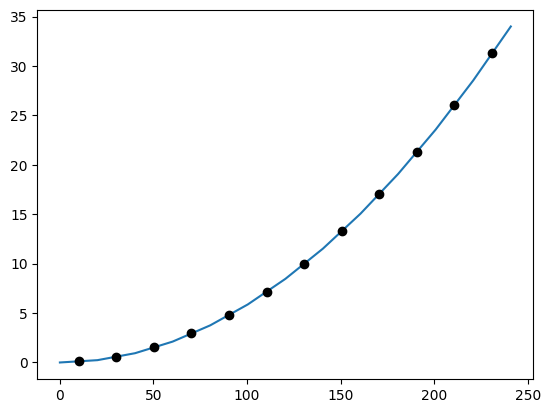

In [74]:
plt.plot(x0, y0)
for i in range(len(q)):
    plt.plot(x_(alp_,i,l),y_(alp_,i,l), 'o', color='black')
plt.show()

In [75]:
q0=[]
for i in range(len(q)):
    q0.append(q[i])
    
for i in range(len(q)):    
    q0.append(0)

In [76]:
dq

array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

In [77]:
q

[0.011682180162146196,
 0.02335798455032465,
 0.02333887461552226,
 0.02330708256566897,
 0.0232626947599852,
 0.023205831300248253,
 0.02313664524184167,
 0.023055321595583544,
 0.02296207613278492,
 0.022857154007963176,
 0.0227408282146499,
 0.022613397892764092]

In [78]:
def static_func(q):
    alp=alpha(q)
    dalp=alpha(dq)
    F_=np.array([-Fx(q,alp,dq,kp, 0, x_ref = X_REF),0]).reshape(2,1)
    ans=  f(q, K)-g(q,alp,dalp) - tau(q,alp, tau_qn, F_, 0) - tau_stinger(q)
    return ans.reshape((len(q),))

def solve_static(q_guess, n_steps=8):
    """fsolve with continuation in the roller stiffness. A stiff penalty started from a cold guess
    can jump to a spurious kinked equilibrium; ramping k_roll up from a soft value avoids that."""
    global k_roll
    k_target = k_roll
    root = np.asarray(q_guess, dtype=float)
    try:
        for k_ in np.geomspace(k_target*1e-3, k_target, n_steps):
            k_roll = k_
            root = fsolve(static_func, root)
    finally:
        k_roll = k_target
    return root

In [79]:
root = solve_static(np.array(q).astype(np.float64))

In [80]:
root

array([ 0.0664611 ,  0.05506468,  0.04283571,  0.03005633,  0.01700249,
        0.00394431, -0.00885183, -0.02112109, -0.032599  , -0.04302276,
       -0.05213557, -0.05761625])

In [81]:
q = list(root) 

In [82]:
q

[0.0664611014118708,
 0.05506468191896703,
 0.042835705768600116,
 0.030056326194536298,
 0.017002485229712358,
 0.003944312941545562,
 -0.008851830413303957,
 -0.02112108761103563,
 -0.03259900331123673,
 -0.04302276491677299,
 -0.05213556568597151,
 -0.05761625375090535]

In [83]:
q0=[]
for i in range(len(q)):
    q0.append(q[i])
    
for i in range(len(q)):  
    q0.append(0)

In [84]:
alp_=alpha(root) 

In [85]:
alp_

array([6.64611014e-02, 1.21525783e-01, 1.64361489e-01, 1.94417815e-01,
       2.11420301e-01, 2.15364613e-01, 2.06512783e-01, 1.85391695e-01,
       1.52792692e-01, 1.09769927e-01, 5.76343615e-02, 1.81077760e-05])

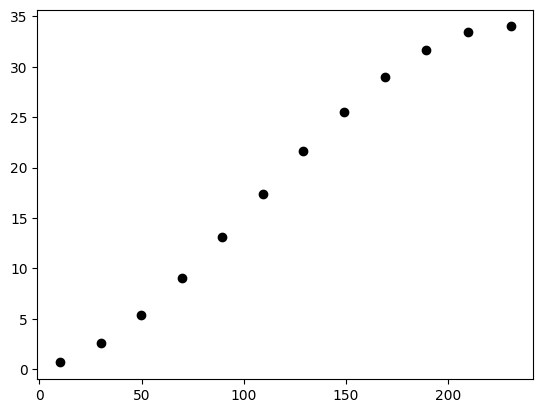

In [86]:
for i in range(len(q)):
    plt.plot(x_(alp_,i,l),y_(alp_,i,l), 'o', color='black')
plt.show()

In [87]:
q0

[0.0664611014118708,
 0.05506468191896703,
 0.042835705768600116,
 0.030056326194536298,
 0.017002485229712358,
 0.003944312941545562,
 -0.008851830413303957,
 -0.02112108761103563,
 -0.03259900331123673,
 -0.04302276491677299,
 -0.05213556568597151,
 -0.05761625375090535,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0]

In [88]:
startTime = datetime.now()

add1=functools.partial(Jv, i=len(q)-1, l=l)
add1__Jv = np.array(list(map(add1, [q])))

add5=functools.partial(f, k=K)
add5__f =np.array(list(map(add5, [q])))

add6=functools.partial(g,alp=alp_, dalp=dalp)
add6__g =np.array(list(map(add6, [q])))

print(datetime.now() - startTime)

0:00:00.002414


In [89]:
tmp__1 = pinv(add1__Jv.transpose(0, 2, 1))
tmp__2 = add5__f + add6__g

In [90]:
tmp__ = np.matmul(tmp__1, tmp__2)

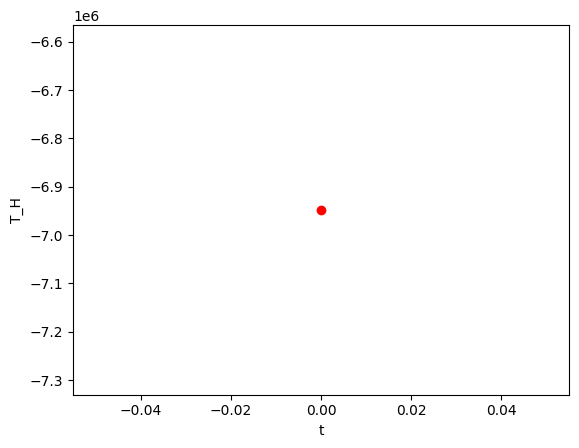

In [91]:
plt.plot(0,tmp__[:,0],'o', color='red')
plt.xlabel('t')
plt.ylabel('T_H')
plt.show()

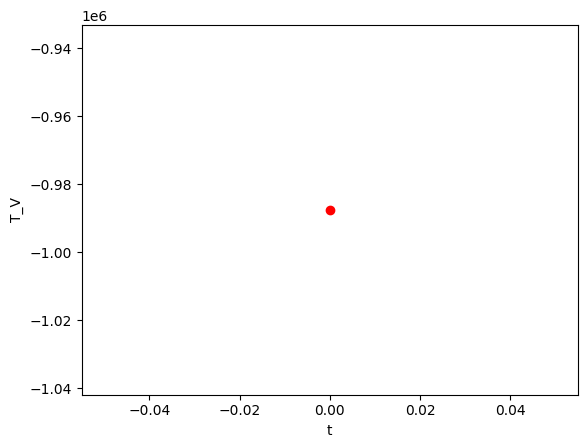

In [92]:
plt.plot(0,tmp__[:,1],'o', color='red')
plt.xlabel('t')
plt.ylabel('T_V')
plt.show()

In [93]:
max(tmp__[:,0]), max(tmp__[:,1])

(array([-6947936.10604174]), array([-987558.78028653]))

### Stinger: roller reactions and tip clearance (static)

roller   gap [m]   reaction [kN]
   1      -0.000          0.0
   2       0.030          0.0
   3       0.119          0.0
   4       0.268          0.0
   5       0.477          0.0
   6       0.504          0.0
   7       0.544          0.0
total roller load = 0.0 kN,  tip clearance = 0.868 m


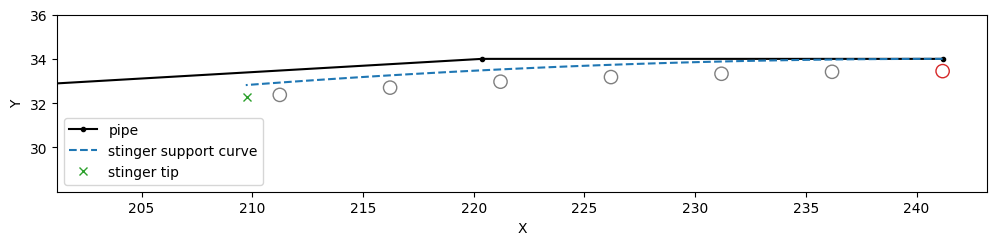

In [94]:
# Stinger: static roller reactions and tip clearance
st = stinger_state(q)
print("roller   gap [m]   reaction [kN]")
for k in range(n_roll):
    print(f"  {k+1:2d}    {st['gap'][k]:8.3f}   {st['F'][k]/1e3:10.1f}")
print(f"total roller load = {st['F'].sum()/1e3:.1f} kN,  tip clearance = {st['tip_clr']:.3f} m")

nodes_ = st['nodes']; arc_ = stinger_to_world(q, stinger_arc_loc())
plt.figure(figsize=(12, 3.5))
plt.plot(nodes_[:, 0], nodes_[:, 1], 'o-', color='black', ms=3, label='pipe')
plt.plot(arc_[:, 0], arc_[:, 1], '--', color='tab:blue', label='stinger support curve')
for k in range(n_roll):
    plt.gca().add_patch(plt.Circle(st['rollers'][k], r_roll, fill=False, color='tab:red' if st['F'][k] > 0 else 'tab:gray'))
plt.plot(*st['tip'], 'x', color='tab:green', label='stinger tip')
plt.xlim(nodes_[-1, 0] - 40, nodes_[-1, 0] + 2); plt.ylim(nodes_[-1, 1] - 6, nodes_[-1, 1] + 2)
plt.gca().set_aspect('equal'); plt.xlabel('X'); plt.ylabel('Y'); plt.legend(); plt.show()

### Dynamic solution 

In [95]:
def dynamic_func( t,Q, q):

    q, dq = Q[0:N], Q[N:]
    QI = q.reshape(len(q),1)
    dQ = dq.reshape(len(q),1)
    
    QI = QI.flatten().tolist()
 
 
    alp = alpha(QI)
    dalp = alpha(dQ.flatten().tolist())

    if t > DP_start:
        F = np.array([-Fx(QI, alp, dQ, kp, kd, x_ref = X_REF),0]).reshape(2,1) 
    else:
        F = np.array([Fx_0, 0]).reshape(2,1)
    
    ddq = np.linalg.solve(M(QI, l, mn, In, mi), 
                        - np.dot(H(alp,QI,dQ,l), dQ).reshape(len(QI),1)
                        - np.dot(C(QI,dQ, l, mn, In, mi), dQ) 
                        - f(QI, K) 
                        - g(QI,alp, dalp) 
                        + tau(QI,alp, tau_qn, F, tau_q_wave)
                        + tau_stinger(QI, dq)).flatten()
      
    ans=np.concatenate([dq, ddq], axis=0)
        
    return ans

In [96]:
q

[0.0664611014118708,
 0.05506468191896703,
 0.042835705768600116,
 0.030056326194536298,
 0.017002485229712358,
 0.003944312941545562,
 -0.008851830413303957,
 -0.02112108761103563,
 -0.03259900331123673,
 -0.04302276491677299,
 -0.05213556568597151,
 -0.05761625375090535]

In [97]:
startTime1 = datetime.now()
us=solve_ivp(dynamic_func, (0,max_t),q0, args=(q,))
print(datetime.now() - startTime1)

0:32:24.704034


In [98]:
us_=us.y.T
t_=us.t

In [99]:
us_.shape

(1096, 24)

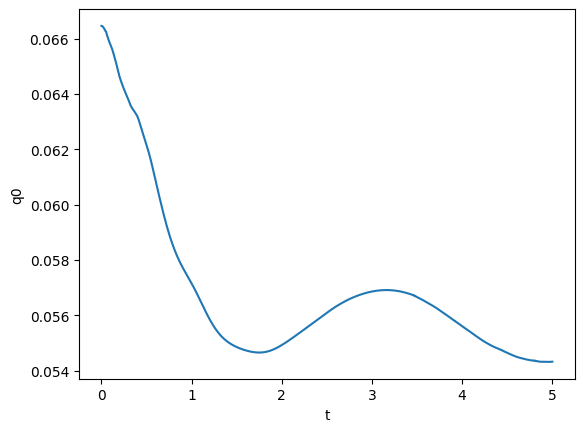

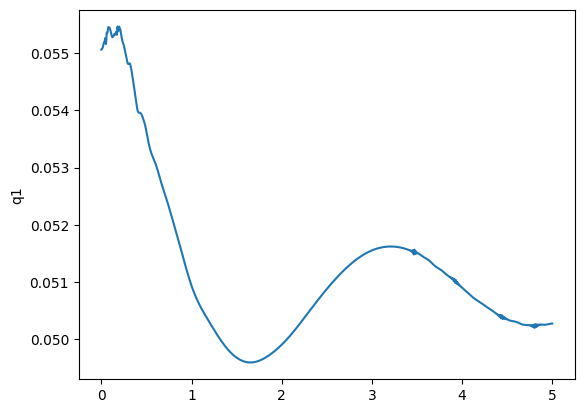

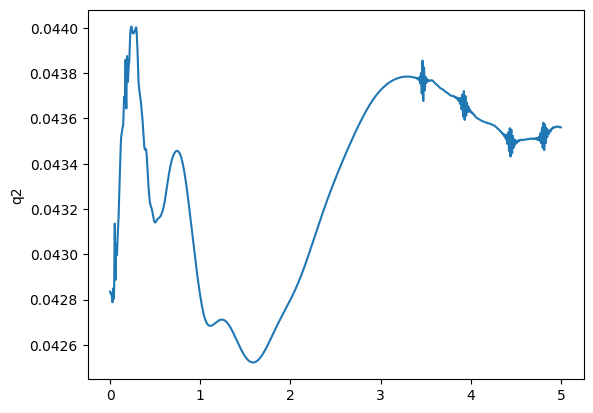

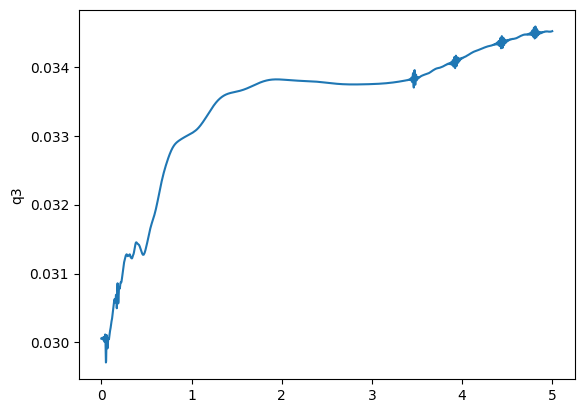

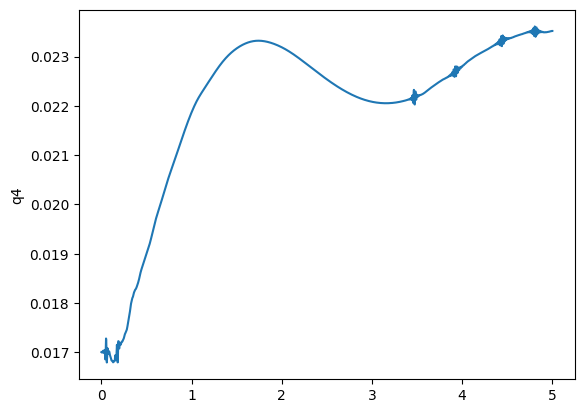

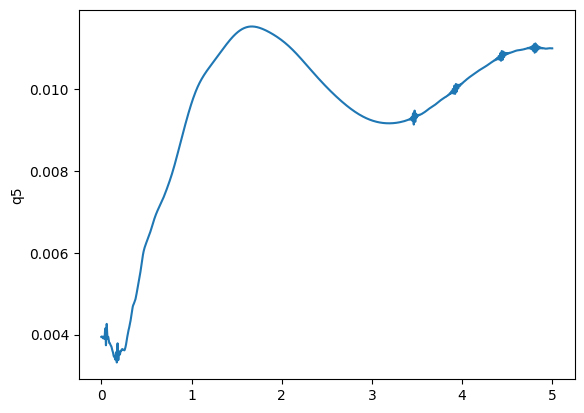

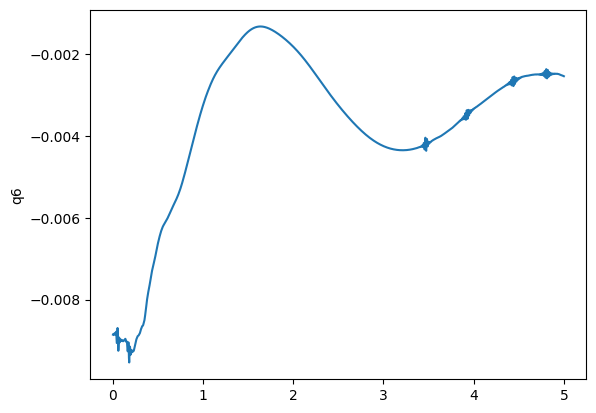

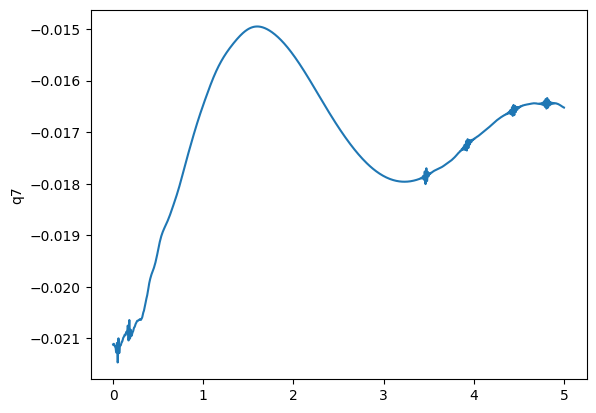

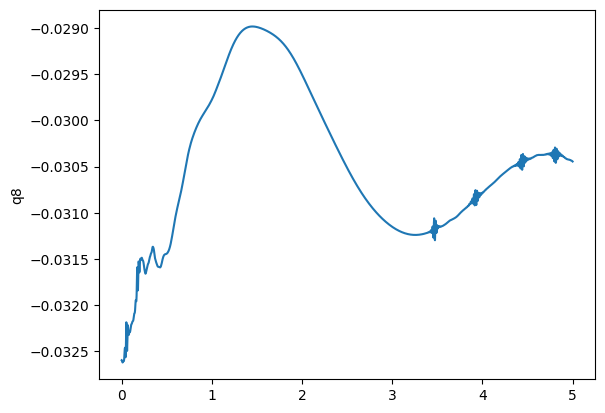

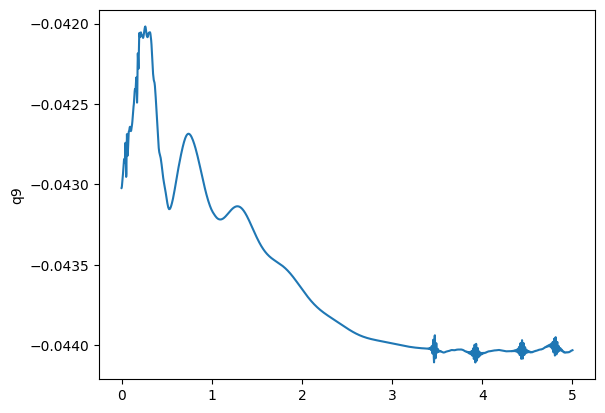

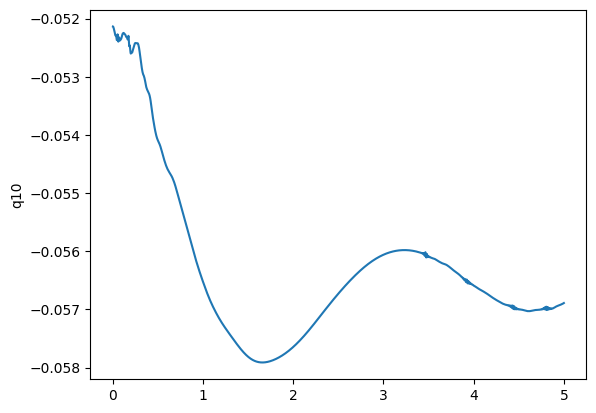

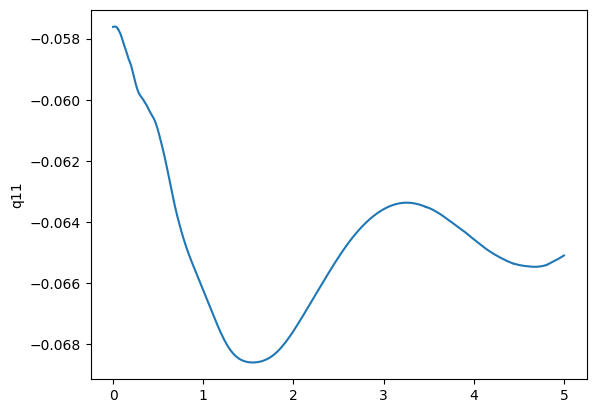

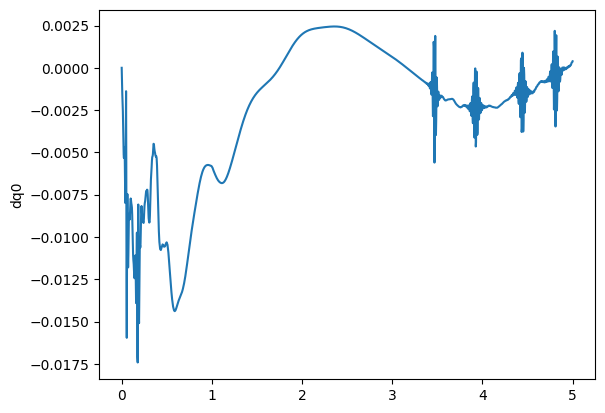

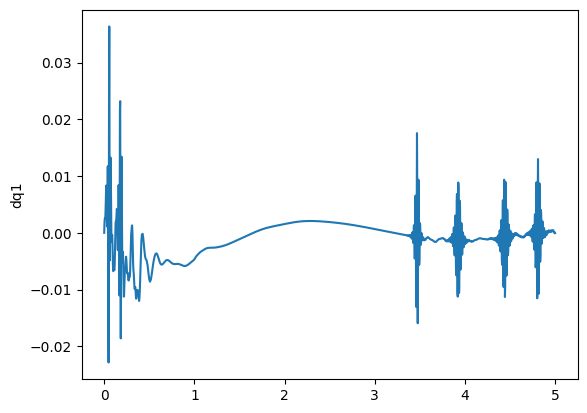

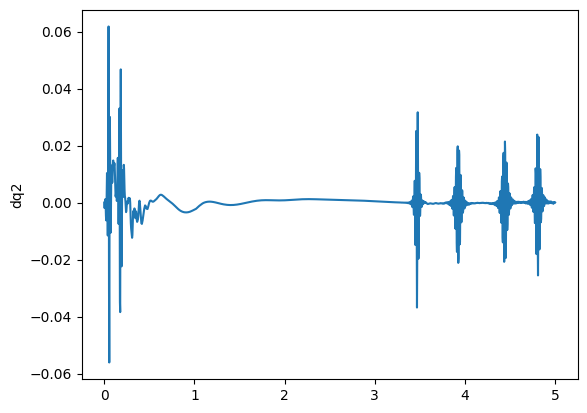

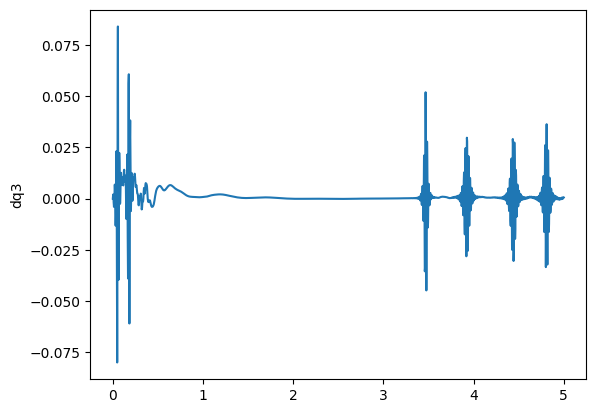

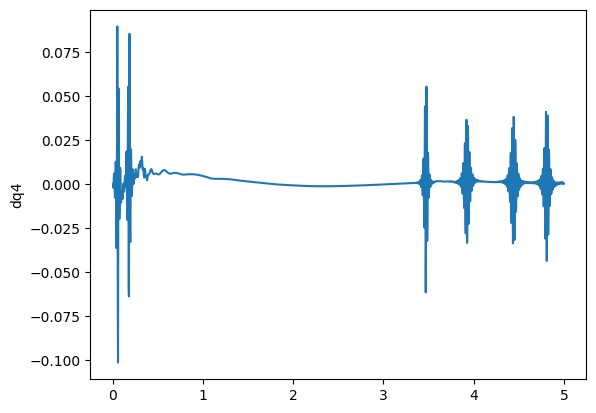

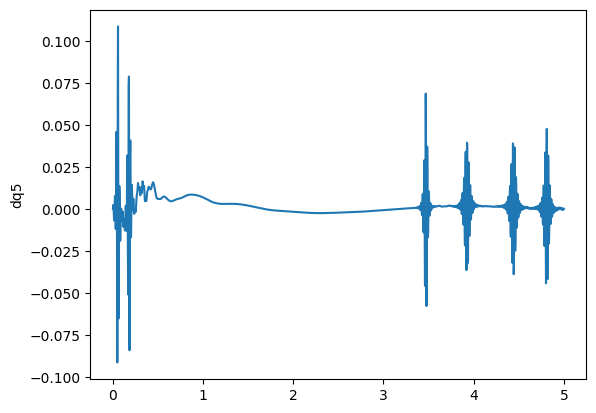

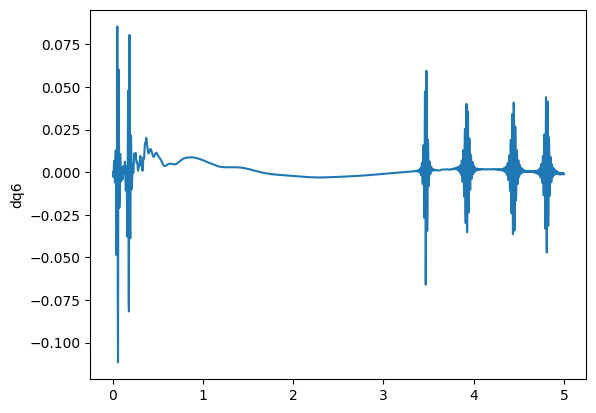

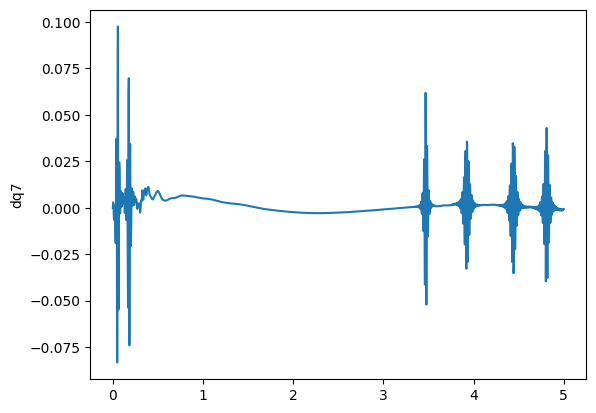

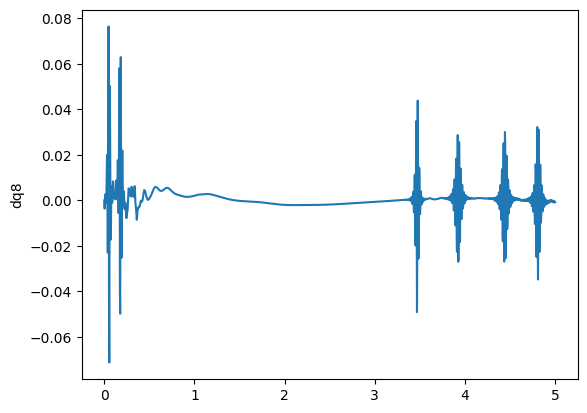

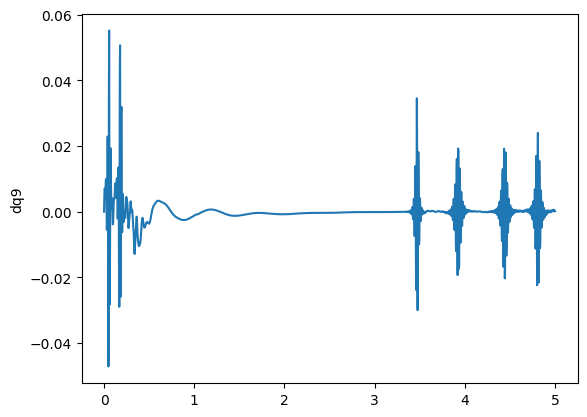

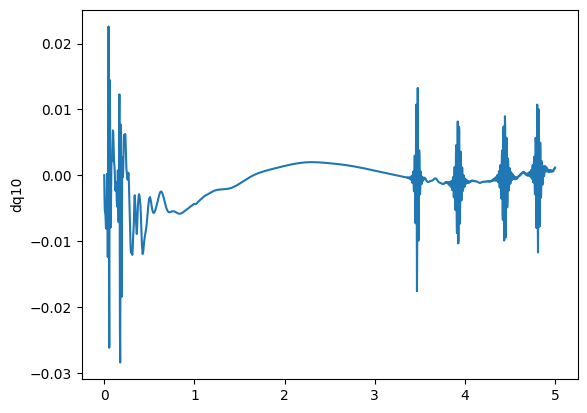

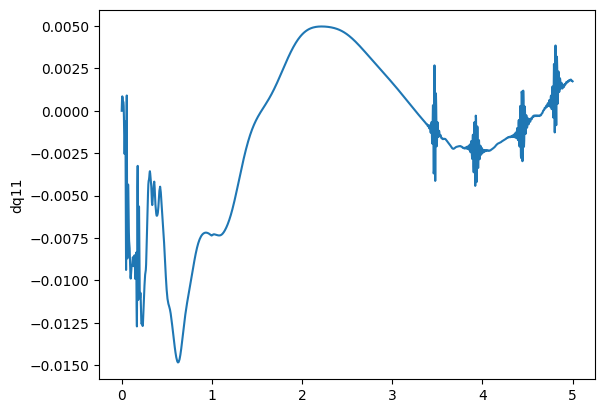

In [100]:
plt.xlabel('t')
for i in range(len(q0)):
    if i<len(q0)//2:
        plt.plot(t_,us_[:,i] ,'-')
        plt.ylabel('q{}'.format(i))
    else:
        plt.plot(t_, us_[:,i],'-')
        plt.ylabel('{}q{}'.format('d',i-len(q)))
    plt.show()        

In [101]:
horizon_start = 0

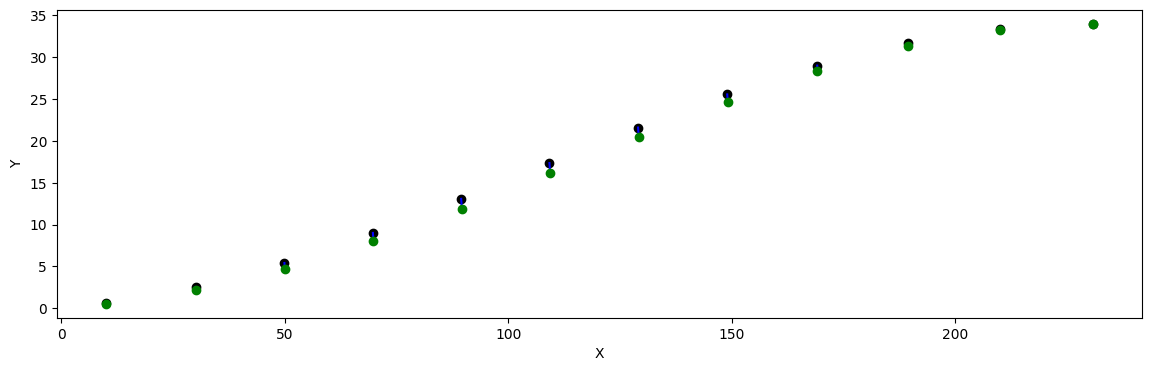

In [102]:
plt.figure(figsize=(14,4))
plt.xlabel('X')
plt.ylabel('Y')

for j in range(len(q)):
    X = [x_(alpha(us_[i,[k for k in range(0,len(q0)//2)]]),j,l) for i in range(horizon_start, len(us_))]
    Y = [y_(alpha(us_[i,[k for k in range(0,len(q0)//2)]]),j,l) for i in range(horizon_start, len(us_))]
    X_ = [x_(alpha(us_[i,[k for k in range(0,len(q0)//2)]]),j,l) for i in range(1)]
    Y_ = [y_(alpha(us_[i,[k for k in range(0,len(q0)//2)]]),j,l) for i in range(1)]
    plt.plot(X_,Y_, 'o', color='black')
    
    # dynamic
    plt.plot(X,Y,'b')   
    
    plt.plot(x_(alpha(us_[-1,[k for k in range(0,len(q0)//2)]]),j,l),
             y_(alpha(us_[-1,[k for k in range(0,len(q0)//2)]]),j,l), 'o', color='green')
plt.show()

### Pipe-tip tension

In [103]:
coordinates=us_[:,[k for k in range(0,len(q0)//2)]]
velocities=us_[:,[k for k in range(len(q0)//2,len(q0))]]

In [104]:
alp_=[]
for i in range(len(us_)):
    alp_.append(alpha(coordinates[i]))
alp_=np.matrix(alp_) 


dalp_=[]
for i in range(len(us_)):
    dalp_.append(alpha(velocities[i]))
dalp_=np.matrix(dalp_)   

In [105]:
velocities.shape

(1096, 12)

In [106]:
velocities_0 = velocities[:-1]
velocities_1 = velocities[1:]

In [107]:
coordinates.shape, velocities.shape

((1096, 12), (1096, 12))

In [108]:
startTime1 = datetime.now()

add4=functools.partial(C, l=l, mn=mn, In=In, mi=mi)
add4__C =np.array(list(map(add4, coordinates, velocities)))

print(datetime.now() - startTime1)

0:03:06.737443


In [109]:
startTime = datetime.now()

add1=functools.partial(Jv, i=len(q)-1, l=l)
add1__Jv = np.array(list(map(add1, coordinates)))

add2=functools.partial(M, l=l, mn=mn, In=In, mi=mi)
add2__M =np.array(list(map(add2, coordinates)))

add3=functools.partial(H,  l=l)
add3__H =np.array(list(map(add3, alp_.tolist(), coordinates, velocities)))

add5=functools.partial(f, k=K)
add5__f =np.array(list(map(add5, coordinates)))

add6=functools.partial(g)
add6__g =np.array(list(map(add6, coordinates, alp_.tolist(),dalp_.tolist())))

print(datetime.now() - startTime)

0:00:02.446839


In [110]:
velocities_1.shape

(1095, 12)

In [111]:
add5__f.shape

(1096, 12, 1)

In [112]:
add6__g.shape

(1096, 12, 1)

In [113]:
add3__H.shape

(1096, 12, 12)

In [114]:
dt=max_t/us_.shape[0]

In [115]:
tmp__1 = pinv(add1__Jv[:-1].transpose(0, 2, 1))
tmp__2 = np.matmul(add2__M[:-1], (velocities_1.reshape(len(velocities_1),len(q),1)
                                  - velocities_0.reshape(len(velocities_0),len(q),1))/dt)\
            + np.matmul(add3__H[:-1], velocities[:-1].reshape(len(velocities_0),len(q),1)) \
            + np.matmul(add4__C[:-1], velocities[:-1].reshape(len(velocities_0),len(q),1)) \
            + add5__f[:-1] \
            + add6__g[:-1]

In [116]:
add1__Jv[:-1].shape

(1095, 2, 12)

In [117]:
tmp__2.shape

(1095, 12, 1)

In [118]:
tmp__=np.matmul(tmp__1, tmp__2)

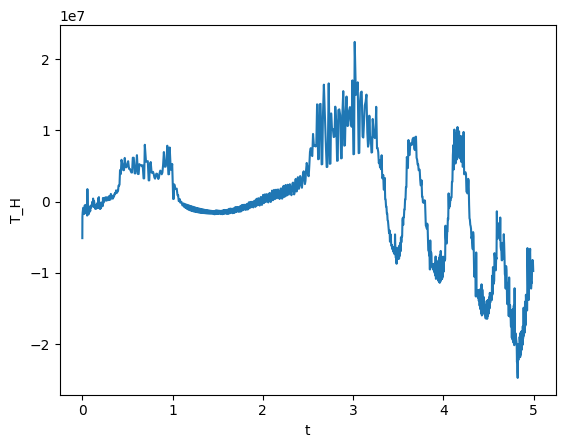

In [119]:
plt.plot(t_[:len(tmp__)],tmp__[:,0],'-')
plt.xlabel('t')
plt.ylabel('T_H')
plt.show()

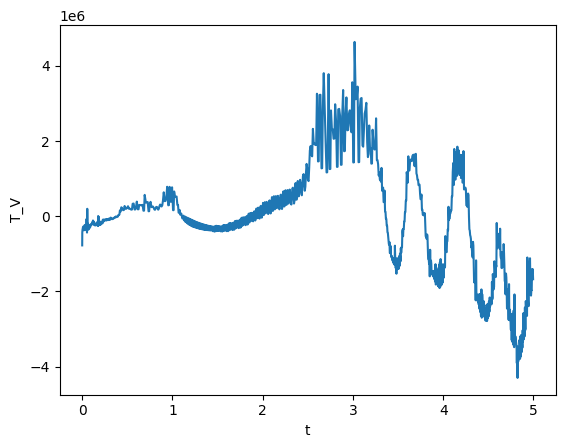

In [120]:
plt.plot(t_[:len(tmp__)],tmp__[:,1],'-')
plt.xlabel('t')
plt.ylabel('T_V')
plt.show()

### Stinger: roller reactions and tip clearance (dynamic)

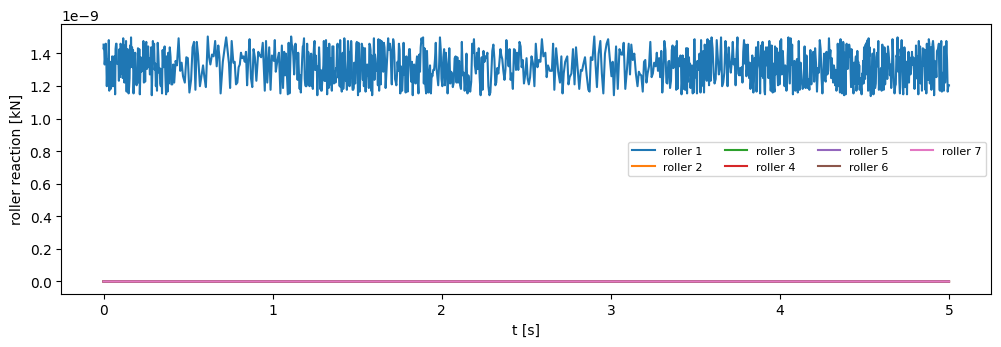

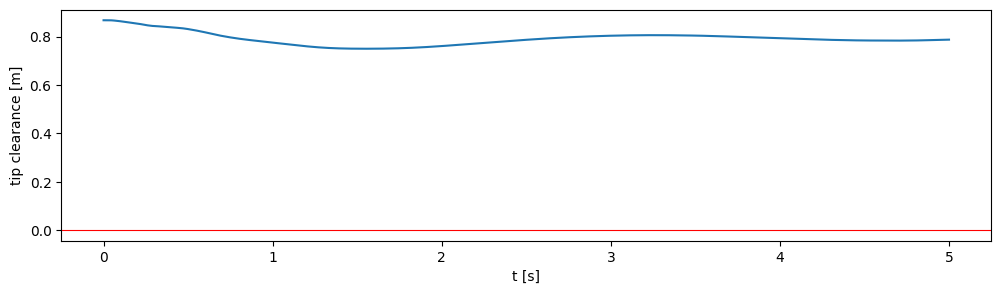

roller   max reaction [kN]   min gap [m]
   1               0.0        -0.000
   2               0.0         0.030
   3               0.0         0.119
   4               0.0         0.268
   5               0.0         0.477
   6               0.0         0.458
   7               0.0         0.443
min tip clearance = 0.750 m at t = 1.55 s


In [121]:
# Stinger: roller reactions and tip clearance over time
st_hist = [stinger_state(coordinates[i], velocities[i]) for i in range(len(coordinates))]
F_roll  = np.array([s['F'] for s in st_hist]) / 1e3        # [kN], shape (n_t, n_roll)
gap_r   = np.array([s['gap'] for s in st_hist])
tip_clr_t = np.array([s['tip_clr'] for s in st_hist])

plt.figure(figsize=(12, 3.5))
for k in range(n_roll):
    plt.plot(t_, F_roll[:, k], label=f'roller {k+1}')
plt.xlabel('t [s]'); plt.ylabel('roller reaction [kN]'); plt.legend(ncol=4, fontsize=8); plt.show()

plt.figure(figsize=(12, 3))
plt.plot(t_, tip_clr_t); plt.axhline(0, color='red', lw=0.8)
plt.xlabel('t [s]'); plt.ylabel('tip clearance [m]'); plt.show()

print("roller   max reaction [kN]   min gap [m]")
for k in range(n_roll):
    print(f"  {k+1:2d}      {F_roll[:, k].max():12.1f}      {gap_r[:, k].min():8.3f}")
print(f"min tip clearance = {tip_clr_t.min():.3f} m at t = {t_[np.argmin(tip_clr_t)]:.2f} s")

In [122]:
# Axial strain

In [123]:
indices = np.where((t_ > 3.5) & (t_<4.0))

In [124]:
Af = 3.14/4*(d0**2-dI**2)

In [125]:
np.max(tmp__[indices[0][0]:indices[0][-1],0])/(E*Af)

0.0008939244438516368

In [126]:
# Top tension
np.max(tmp__[indices[0][0]:indices[0][-1],0]) 

9107692.431980219

In [127]:
# Bending strain

In [128]:
c=d0/2

In [129]:
M_joint = [EI * abs(q[i]) / l[i] for i in range(N-1)] # Bending moment at each joint i
eps_bending_max = max(abs(q[i]) / l[i] for i in range(N-1)) * c

In [130]:
eps_bending_max

0.000840663460196296

In [131]:
# Hs

In [132]:
X111 = [x_(alpha(us_[i,[k for k in range(0,len(q0)//2)]]),N-4,l) for i in range(0, len(us_))]
Y111 = [y_(alpha(us_[i,[k for k in range(0,len(q0)//2)]]),N-4,l) for i in range(0, len(us_))]
X111_ = [x_(alpha(us_[i,[k for k in range(0,len(q0)//2)]]),N-4,l) for i in range(1)]
Y111_ = [y_(alpha(us_[i,[k for k in range(0,len(q0)//2)]]),N-4,l) for i in range(1)]

In [133]:
(np.max(Y111)-np.min(Y111))

0.7570147226812054

In [134]:
X1111 = [x_(alpha(us_[i,[k for k in range(0,len(q0)//2)]]),N-3,l) for i in range(0, len(us_))]
Y1111 = [y_(alpha(us_[i,[k for k in range(0,len(q0)//2)]]),N-3,l) for i in range(0, len(us_))]
X1111_ = [x_(alpha(us_[i,[k for k in range(0,len(q0)//2)]]),N-3,l) for i in range(1)]
Y1111_ = [y_(alpha(us_[i,[k for k in range(0,len(q0)//2)]]),N-3,l) for i in range(1)]

In [135]:
(np.max(Y1111)-np.min(Y1111))

0.41123016997567774

In [136]:
X010=[]
Y010=[]

In [137]:
for j in range(len(q)):
    X = [x_(alpha(us_[i,[k for k in range(0,len(q0)//2)]]),j,l) for i in range(horizon_start, len(us_))]
    Y = [y_(alpha(us_[i,[k for k in range(0,len(q0)//2)]]),j,l) for i in range(horizon_start, len(us_))]
    X010.append(X)
    Y010.append(Y)

In [138]:
X010=np.array(X010).T
Y010=np.array(Y010).T

In [139]:
X010.shape 

(1096, 12)

In [140]:
# simulation = np.stack([X010, Y010], axis=2) 

# FPS = 6                      
# frame_duration = 1000 / FPS

# frames = []
# for t in range(simulation.shape[0]):
#     x = simulation[t,:,0]
#     y = simulation[t,:,1]

#     frames.append(go.Frame(
#         data=[
#             go.Scatter(
#                 x=x, y=y,
#                 mode="lines+markers",
#                 marker=dict(size=5, color=list(range(12)), colorscale="Viridis"),
#                 line=dict(width=4)
#             )
#         ],
#         name=f"t={t}"
#     ))

# # First frame
# x0, y0  = simulation[0,:,0], simulation[0,:,1]

# fig = go.Figure(
#     data=[go.Scatter(x=x0, y=y0, mode="lines+markers")],
#     frames=frames
# )

# # Animation controls
# fig.update_layout(
#     title="Pipeline Simulation ",
#     scene=dict(
#         xaxis_title="X",
#         yaxis_title="Y",
#         xaxis=dict(range=[0, 300]),
#         yaxis=dict(range=[0, 40]),
#         aspectmode="data",
       
#     ),
#     updatemenus=[{
#         "type": "buttons",
#         "buttons": [
#             {
#                 "label": "Play",
#                 "method": "animate",
#                 "args": [None, {"frame": {"duration": frame_duration, "redraw": True}}]
#             },
#             {
#                 "label": "Pause",
#                 "method": "animate",
#                 "args": [[None], {"frame": {"duration": 0}}]
#             }
#         ]
#     }]
# )

# fig.show()